# Experiments and failure analysis

Phase 1 completed nine real-data adapter fits. All three procedures failed the frozen validation promotion rule, so frozen CLIP was retained. These are validation results, not test scores. A separate validation-only loss hypothesis is being prepared; global test release remains closed.

In [1]:
from pathlib import Path
import json,hashlib,collections
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,HTML
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
assert (ROOT/'src').exists()
import os
os.chdir(ROOT)
def read(path):return json.loads(Path(path).read_text(encoding='utf-8'))
def table(rows,title):
    if not rows:return
    columns=list(rows[0]);html='<h4>'+title+'</h4><table><tr>'+''.join('<th>'+c+'</th>' for c in columns)+'</tr>'
    for row in rows:html+='<tr>'+''.join('<td>'+str(row[c])+'</td>' for c in columns)+'</tr>'
    display(HTML(html+'</table>'))
def save_plot(name):
    plt.tight_layout();Path('docs/figures').mkdir(exist_ok=True)
    plt.savefig('docs/figures/'+name+'.png',dpi=150)
    plt.show()
SOURCE=Path('data/processed/didemo-v2')
CACHE=Path('data/interim/cloud-smoke-output-v1/video-smoke')
RUN_ENCODER=False
RUN_TRAINING=False
RUN_TEST=False


split,inspected,geometry_valid
train,365,364
val,73,73
test,47,47


Rejected source: One train video declared six bins but actual duration24.17 seconds; sixth bin has no real frames.
Policy: Exclude whole inconsistent source before outcomes; no padding, target remapping or scored replacement.


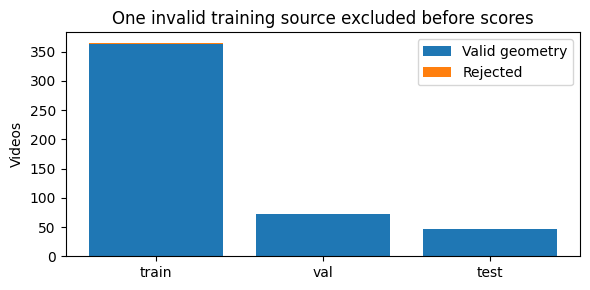

In [2]:
decoder=read('docs/decoder-preflight.json')
table([{'split':s,**r} for s,r in decoder['all_media_inspected'].items()],'All-source decoder preflight')
print('Rejected source:',decoder['failure'])
print('Policy:',decoder['policy'])
fig,ax=plt.subplots(figsize=(6,3));rows=decoder['all_media_inspected'];names=list(rows)
ax.bar(names,[rows[s]['geometry_valid'] for s in names],label='Valid geometry')
ax.bar(names,[rows[s]['inspected']-rows[s]['geometry_valid'] for s in names],bottom=[rows[s]['geometry_valid'] for s in names],label='Rejected')
ax.set(ylabel='Videos',title='One invalid training source excluded before scores');ax.legend();save_plot('decoder-audit')


In [3]:
receipt=read('docs/video-smoke.json')
table([{'check':k,'value':v} for k,v in receipt['encoder']['loading_info'].items()],'Actual pretrained loading diagnostics')
table([{'check':'Encoder cache replay','maximum absolute difference':receipt['feature_replay_max_abs_error']},
       {'check':'Adapter checkpoint replay','maximum absolute difference':receipt['adapter_training']['checkpoint_replay_max_abs_error']}],'Actual remote save/reload checks')


check,value
missing_keys,[]
unexpected_keys,[]
mismatched_keys,[]
error_msgs,[]


check,maximum absolute difference
Encoder cache replay,2.9802322387695312e-08
Adapter checkpoint replay,0.0


## Completed full-run analysis
Set FULL_RUN only to a downloaded, hash-verified output directory. Inspect every validation configuration and seed, not a favorable example. A different candidate corpus cannot be compared as if only model weights changed.

procedure,corpus R@1,corpus R@5,video R@1,within-video mIoU
frozen_clip,0.153257,0.237548,0.337165,0.376905
lr001,0.130268,0.252874,0.367816,0.336909
lr0003,0.141762,0.268199,0.375479,0.357301
decay01,0.130268,0.252874,0.367816,0.336654


Selected: frozen_clip actual training seconds: 36.893320581000125
Saved checkpoint SHA256: f6497534a17e3f0fc4af67a9ce9b96cf1bfc4208a54bcc125ec7ad766938bfdb replay max difference: 0.0


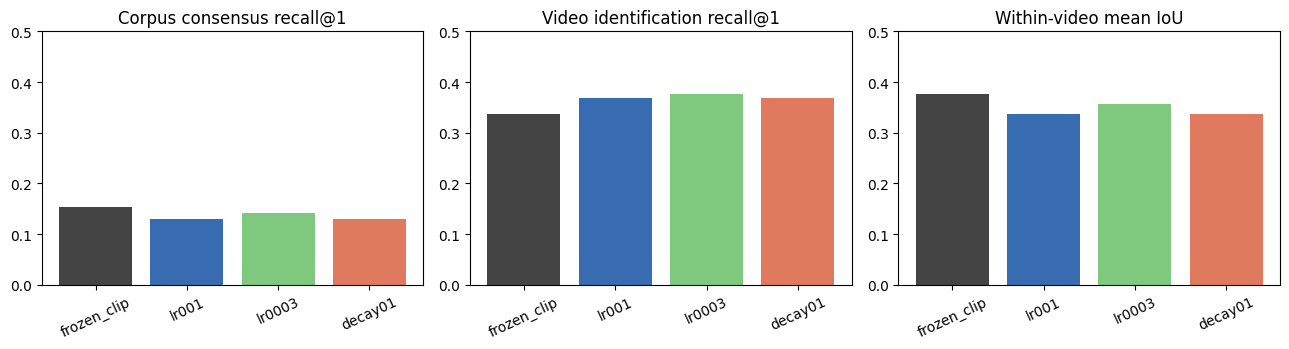

In [4]:
phase1=read('docs/phase1-validation-results.json')
assert phase1['test_targets_used'] is False
assert phase1['selected']=='frozen_clip'
rows=[{'procedure':'frozen_clip','metrics':phase1['baseline']}]+[{'procedure':r['config']['name'],'metrics':r['validation']} for r in phase1['runs']]
table([{'procedure':r['procedure'],'corpus R@1':round(r['metrics']['corpus_consensus_r1_iou50'],6),
        'corpus R@5':round(r['metrics']['corpus_consensus_r5_iou50'],6),'video R@1':round(r['metrics']['corpus_video_r1'],6),
        'within-video mIoU':round(r['metrics']['within_video_official_miou'],6)} for r in rows],
      'Actual phase-1 validation: 261 queries / 1,431 candidate moments')
print('Selected:',phase1['selected'],'actual training seconds:',phase1['seconds'])
print('Saved checkpoint SHA256:',phase1['selected_checkpoint_sha256'],'replay max difference:',phase1['checkpoint_replay_max_abs_error'])
fig,axes=plt.subplots(1,3,figsize=(13,3.6))
for ax,key,title in zip(axes,['corpus_consensus_r1_iou50','corpus_video_r1','within_video_official_miou'],
                         ['Corpus consensus recall@1','Video identification recall@1','Within-video mean IoU']):
    ax.bar([r['procedure'] for r in rows],[r['metrics'][key] for r in rows],color=['#444444','#386cb0','#7fc97f','#e07a5f'])
    ax.set(ylim=(0,.5),title=title);ax.tick_params(axis='x',rotation=25)
save_plot('phase1-validation-comparison')


## Actual optimization histories
Every seed is shown. Best epochs were selected on validation, which therefore is not an unbiased final test. Falling training loss alone did not establish better moment retrieval.

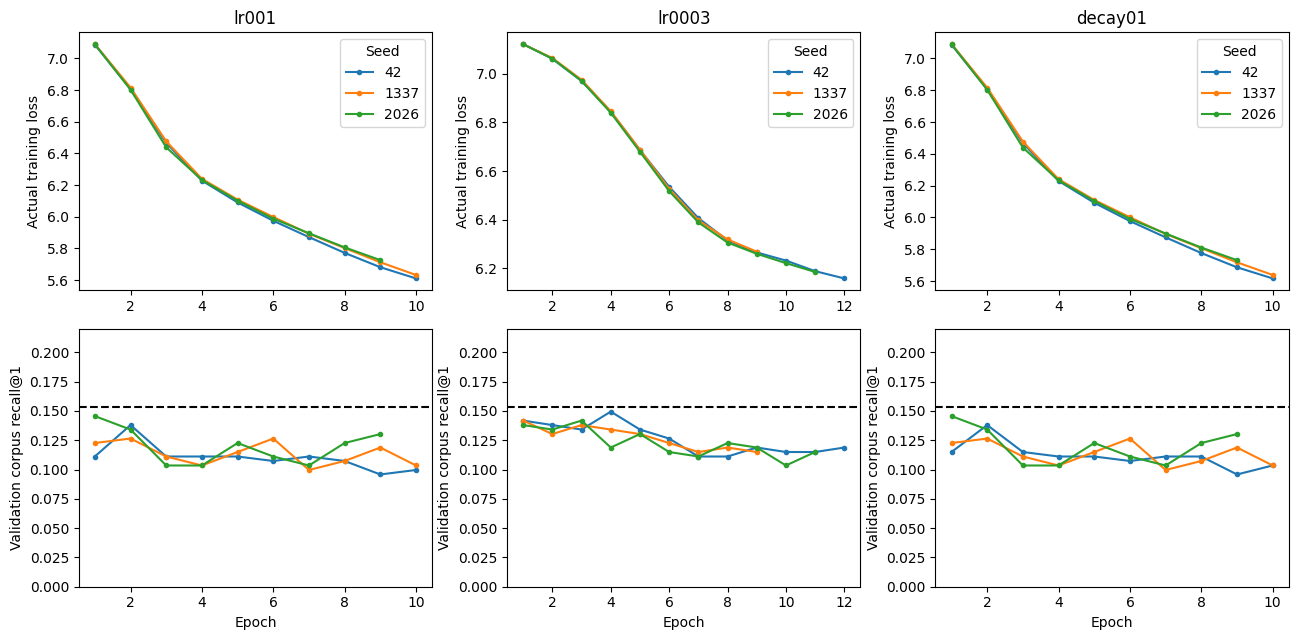

procedure,seed,best epoch,epochs completed,promotion eligible
lr001,42,2,10,False
lr001,1337,2,10,False
lr001,2026,1,9,False
lr0003,42,4,12,False
lr0003,1337,1,9,False
lr0003,2026,3,11,False
decay01,42,2,10,False
decay01,1337,2,10,False
decay01,2026,1,9,False


In [5]:
fig,axes=plt.subplots(2,3,figsize=(13,6.5))
for j,run in enumerate(phase1['runs']):
    for seed in run['seeds']:
        h=seed['history'];epochs=[r['epoch'] for r in h]
        axes[0,j].plot(epochs,[r['train_loss'] for r in h],marker='.',label=str(seed['seed']))
        axes[1,j].plot(epochs,[r['validation_corpus_consensus_r1_iou50'] for r in h],marker='.',label=str(seed['seed']))
    axes[0,j].set(title=run['config']['name'],ylabel='Actual training loss');axes[0,j].legend(title='Seed')
    axes[1,j].axhline(phase1['baseline']['corpus_consensus_r1_iou50'],color='black',linestyle='--',label='Frozen CLIP')
    axes[1,j].set(xlabel='Epoch',ylabel='Validation corpus recall@1',ylim=(0,.22))
save_plot('phase1-nine-fit-histories')
table([{'procedure':r['config']['name'],'seed':s['seed'],'best epoch':s['best_epoch'],
        'epochs completed':len(s['history']),'promotion eligible':r['promotion_eligible']} for r in phase1['runs'] for s in r['seeds']],
      'Every actual fit and selection outcome')


## Failure categories
Decoder geometry can invalidate a source before scoring. Human references can have no consensus-positive candidate. Frozen CLIP can miss temporal order or small actions; averaged frames may erase brief events. Adapter improvements on available footage would not establish full-benchmark or unseen-domain performance. Exact hashes verify replay consistency, not semantic correctness.

The slow-learning-rate procedure improves video identification but loses temporal overlap. None meets the preregistered corpus-recall/IoU promotion rule. This motivates a prospectively recorded validation-only loss comparison; it does not authorize using test outcomes to redesign the model.

## Phase 2: conditional loss and score mixtures

This is a prospective validation-only follow-up motivated by phase-1 video identification improving while temporal overlap fell. It reuses validation for stopping and policy selection; no independent generalization gain is claimed. Weighted losses with different lambda are not directly comparable in magnitude.

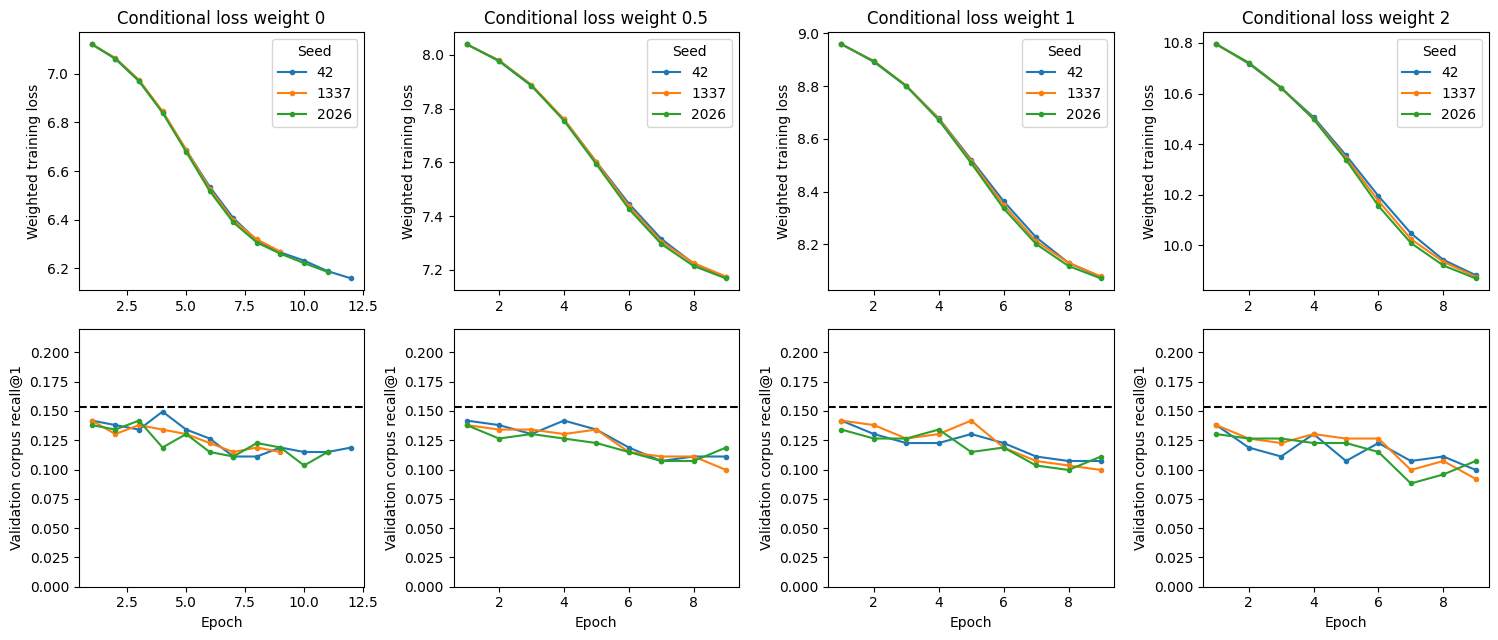

conditional loss weight,seed,best epoch,epochs completed
0,42,4,12
0,1337,1,9
0,2026,3,11
0.5,42,1,9
0.5,1337,1,9
0.5,2026,1,9
1,42,1,9
1,1337,1,9
1,2026,1,9
2,42,1,9


In [6]:
phase2=read('docs/localization-v2-results.json')
assert phase2['test_targets_used'] is False
assert not any(p['promotion_eligible'] for p in phase2['policies'])
fig,axes=plt.subplots(2,4,figsize=(15,6.5))
for j,run in enumerate(phase2['runs']):
    for seed in run['seeds']:
        h=seed['history'];epochs=[r['epoch'] for r in h]
        axes[0,j].plot(epochs,[r['train_loss'] for r in h],marker='.',label=str(seed['seed']))
        axes[1,j].plot(epochs,[r['validation_corpus_consensus_r1_iou50'] for r in h],marker='.')
    axes[0,j].set(title='Conditional loss weight '+str(run['lambda']),ylabel='Weighted training loss');axes[0,j].legend(title='Seed')
    axes[1,j].axhline(phase2['baseline']['corpus_consensus_r1_iou50'],color='black',linestyle='--')
    axes[1,j].set(xlabel='Epoch',ylabel='Validation corpus recall@1',ylim=(0,.22))
save_plot('phase2-twelve-fit-histories')
table([{'conditional loss weight':r['lambda'],'seed':s['seed'],'best epoch':s['best_epoch'],'epochs completed':len(s['history'])}
       for r in phase2['runs'] for s in r['seeds']],'All 12 real fits; recorded histories')


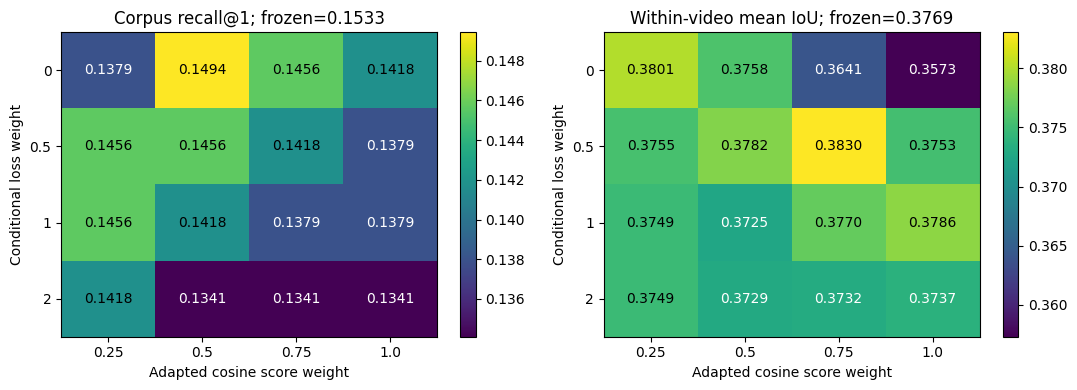

lambda,adapted score weight,corpus R@1,within-video mIoU,promotion eligible
0,0.25,0.137931,0.380098,False
0,0.5,0.149425,0.375841,False
0,0.75,0.145594,0.36407,False
0,1.0,0.141762,0.357301,False
0.5,0.25,0.145594,0.3755,False
0.5,0.5,0.145594,0.378246,False
0.5,0.75,0.141762,0.383035,False
0.5,1.0,0.137931,0.375309,False
1,0.25,0.145594,0.374862,False
1,0.5,0.141762,0.372499,False


Selected: frozen_clip actual phase2 seconds: 186.159267799987 checkpoint replay error: 0.0


In [7]:
weights=[0,.5,1,2];alphas=[.25,.5,.75,1.]
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,key,title in zip(axes,['corpus_consensus_r1_iou50','within_video_official_miou'],['Corpus recall@1','Within-video mean IoU']):
    values=np.array([[next(p['validation'][key] for p in phase2['policies'] if p['lambda']==w and p['adapted_score_weight']==a) for a in alphas] for w in weights])
    im=ax.imshow(values,cmap='viridis',aspect='auto');ax.set_xticks(range(4),alphas);ax.set_yticks(range(4),weights)
    ax.set(xlabel='Adapted cosine score weight',ylabel='Conditional loss weight',title=title+'; frozen='+str(round(phase2['baseline'][key],4)))
    for i in range(4):
        for j in range(4):ax.text(j,i,f'{values[i,j]:.4f}',ha='center',va='center',color='white' if values[i,j]<values.mean() else 'black')
    fig.colorbar(im,ax=ax)
save_plot('phase2-sixteen-policy-grid')
table([{'lambda':p['lambda'],'adapted score weight':p['adapted_score_weight'],'corpus R@1':round(p['validation']['corpus_consensus_r1_iou50'],6),
        'within-video mIoU':round(p['validation']['within_video_official_miou'],6),'promotion eligible':p['promotion_eligible']} for p in phase2['policies']],
      'All 16 validation score policies; none qualifies')
print('Selected:',phase2['selected'],'actual phase2 seconds:',phase2['seconds'],'checkpoint replay error:',phase2['checkpoint_replay_max_abs_error'])


## Interpretation

The highest phase-2 corpus recall is 0.149425 (lambda 0, adapter score weight .5), below frozen CLIP 0.153257. A different mixture improves mean IoU to 0.383035 but lowers corpus recall to 0.141762. These diagnose a tradeoff rather than a promoted model. Both controlled training rounds remain visible; final test release requires a separate global policy freeze. No test outcomes informed these choices.